# **<font color="PINK">------</font>** **<font color="PALEVIOLETRED">DIFERENCIAS</font>** **<font color="PALEVIOLETRED">DIVIDIDAS</font>** **<font color="PINK">------</font>**

***<font color="PALEVIOLETRED">NOMBRE:</font>*** **CUEVAS COYAZO ISABELLA**

***<font color="PINK">GRUPO:</font>*** **3MV1**

**<font color="PINK">>>></font>** **<font color="PALEVIOLETRED">DEFINICION</font>** **<font color="PINK"><<<</font>**

**<font color="PINK"> - </font>** Con este metodo podemos calcular las diferencias divididas de manera progresiva para que asi podamos obtener los coeficientes del polinomio interpolante, tambien para poder aplicarlo se utiliza los nodos **<font color="PALEVIOLETRED"> ${X_i}$ </font>** y los valores dados de la funcion.

**<font color="PINK"> - </font>** Por lo tanto su formula para calcular las diferencias divididas es: **<font color="PALEVIOLETRED"> $${f[x_i,x_{i-1},\ldots,x_{i-j}]=\frac{f[x_i,x_{i-1},\ldots,x_{i-j+1}]-f[x_{i-1},x_{i-2},\ldots,x_{i-j}]}{x_i-x_{i-j}}}$$ </font>**

**<font color="PINK"> - </font>** Tambien los coeficientes del polinomio los obtenemos de la diagonal de la tabla de diferencias divididas y cada coeficiente lo multiplicamos por los factores correspondientes para formar los términos del polinomio de Newton: **<font color="PALEVIOLETRED"> $${P_n(x)=f[X_0]+f[X_0,X_1](X-X_0)+f[X_0,X_1,X_2](X-X_0)(X-X_1)+...+f[X_0,...,X_n](X-X_j}$$</font>**

**<font color="PINK">>>></font>** **<font color="PALEVIOLETRED">EJERCICIO</font>** **<font color="PINK"><<<</font>**

**<font color="PINK"> - </font>** Complete la tabla de diferencias divididas para los datos utilizados en el **<font color="pink"> ejemplo 1 de la sección 3.2 y reproducidos en la tabla 3.10 </font>**, y construya el polinomio de interpolación que
usa todos estos datos. 

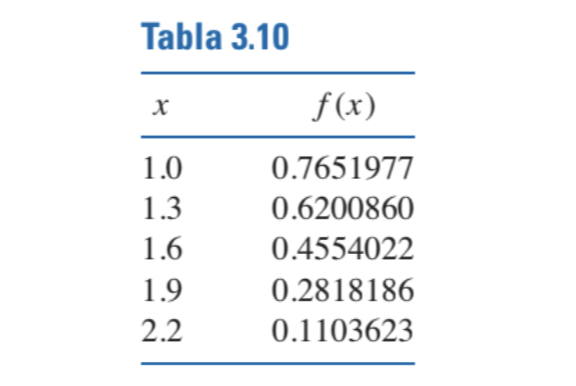

 **<font color="PINK">-----------------------------------</font>** **<font color="PALEVIOLETRED">CODIGO</font>** **<font color="PINK">----------------------------------</font>**

**<font color="pink">1- </font>** **Importamos las librerias: numpy que nos ayuda ya que contiene funciones matematicas, matplotlib.pyplot nos permite realizar graficas, sympy nos permite trabajar con expresiones matematicas simbolicas**

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from sympy import *

**<font color="pink">2- </font>** **Ahora definimos en listas los valores y nodos dados en el ejercicio de la tabla 3.10**

In [34]:
#valores de la funcion
valores=[0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

#nodos
xi=[1,1.3,1.6,1.9,2.2]

#cantidad de nodos 
n=len(xi)

**<font color="pink">3- </font>** **Definimos la funcion que contiene el procedimiento de diferencias dividas**

In [35]:
def difdivididas(xi, valores):

#cuenta la cantidad de nodos en la lista para saber el tamaño de la matriz (tabla)    
    n=len(xi)

#hacemos una matriz F de 5*5 de solo ceros para agregar los calculos de diferencias divididas
    F=[[0.0 for j in range(n)] for i in range(n)]

#agregamos la lista de los valores en la primera columna de la matriz (tabla)
    for i in range(n):
        F[i][0]=valores[i]

    for j in range(1,n): #columna
        for i in range(j,n): #fila

#aplicamos la formula de las diferencias divididas
            F[i][j] = (F[i][j-1] - F[i-1][j-1]) / (xi[i] - xi[i-j])

#localiza los elementos de la diagonal de la tabla, que corresponde a los coeficientes del polinomio de newton
    a=[F[i][i] for i in range(n)]

#regresamos la tabla F y los coeficientes a
    return F,a 

**<font color="pink">4- </font>** **Tabla.**

In [36]:
#los resultados de la funcion de difdivididas lo guardamos en F y a
F, a=difdivididas(xi, valores)

print("                                                         DIFERENCIAS DIVIDIDAS")
print()

#lista del encabezado de la tabla
encabezados=["i","xi","f[Xi]", "1a diferencia", "2a diferencia", "3a diferencia", "4a diferencia"]

#mostramos los encabezados en orden 
for encabezado in encabezados:
    print(f"{encabezado:>17}", end="")
print("")

#mostramos el numero de fila y nodos de cada uno
for i in range(n):
    print(f"{i:>17}", end="")
    print(f"{xi[i]:>17.1f}", end="")
    
#recorremos las columnas de la matriz
    for j in range(n):
        if j<=i:   #si la columna no es mayor que la fila, se imprime el resultado
            print(f"{F[i][j]:>17.7f}", end="")

#dejamos un espacio vacio si es lo contrario
        else:
            print(f"{'':>17}", end="")
    print()

                                                         DIFERENCIAS DIVIDIDAS

                i               xi            f[Xi]    1a diferencia    2a diferencia    3a diferencia    4a diferencia
                0              1.0        0.7651977                                                                    
                1              1.3        0.6200860       -0.4837057                                                   
                2              1.6        0.4554022       -0.5489460       -0.1087339                                  
                3              1.9        0.2818186       -0.5786120       -0.0494433        0.0658784                 
                4              2.2        0.1103623       -0.5715210        0.0118183        0.0680685        0.0018251


**<font color="pink">5- </font>** **MOSTRAMOS LOS COEFICIENTES QUE ESTAN EN LA DIAGONAL PRINCIPAL DE LA TABLA LOS CUALES CORRESPONDEN A LOS COEFICIENTES DEL POLINOMIO DE NEWTON**

In [37]:
print("COEFICIENTES DEL POLINOMIO")
print("")

for k in range(len(a)): #recorre la lista a para mostrar cada coeficiente
    print(f"a{k}={a[k]:.7f}")

COEFICIENTES DEL POLINOMIO

a0=0.7651977
a1=-0.4837057
a2=-0.1087339
a3=0.0658784
a4=0.0018251


**<font color="pink">6- </font>** **CONSTRUIMOS EL POLINOMIO DE NEWTON**

In [38]:
x=symbols('x') #definimos x como una variable simbolica para construir el polinomio

#hacemos una funcion que recibe los coeficientes y los nodos
def polinewton(a,xi):

    p=0 #iniciamos el polinomio en 0

    print("POLINOMIO DE NEWTON")
    print(" ")

    expresion=f"P_{len(a)-1}(x)=" #creamos un texto para mostrar el polinomio

    for k in range(len(a)): #recorre todos los coeficientes de la lista a
        termino=a[k] #tomamos el coeficiente que corresponde a 
        
        for j in range(k):
            termino=termino*(x-xi[j]) #suma un factor mas a cada termino 
        p=p+termino

        if k==0: #identifica  el primer coeficiente
            expresion +=f"{a[k]:.7f}"
        elif a[k]>=0: #si el coeficiente es positivo se escribe un signo +
            expresion +=f"+{a[k]:.7f}"
        else: #si el coeficiente es negativo se escribe un signo -
            expresion +=f"-{abs(a[k]):.7f}"
            
        for j in range(k):
            expresion += f"(x - {xi[j]})"

    print(expresion)

    return p
            

 **<font color="pink">--------------------------------------------</font>** **<font color="PALEVIOLETRED">GRAFICA</font>** **<font color="pink">------------------------------------------</font>**

POLINOMIO DE NEWTON
 
P_4(x)=0.7651977-0.4837057(x - 1)-0.1087339(x - 1)(x - 1.3)+0.0658784(x - 1)(x - 1.3)(x - 1.6)+0.0018251(x - 1)(x - 1.3)(x - 1.6)(x - 1.9)


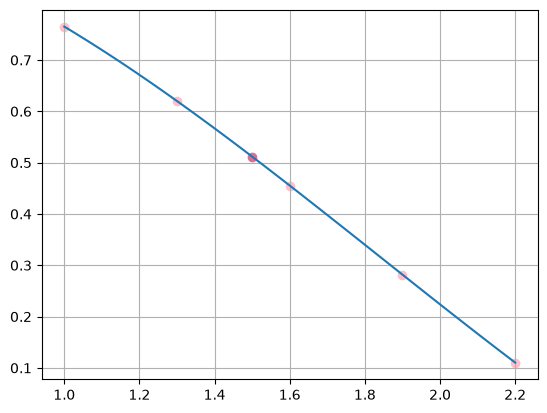

In [39]:
#Guardamos la funcion de polinewton en p 
p=polinewton(a,xi)

xx=np.linspace(min(xi), max(xi), 100) #puntos de la grafica

funcion=lambdify(x,p,'numpy') #convertimos el polinomio en una funcin numerica 
yy=funcion(xx)

x_aprox=1.5
resultado=float(p.subs(x,x_aprox))

plt.plot(xx,yy) #curva del polinomio 
plt.scatter(xi, valores, color="pink") #nodos
plt.scatter(x_aprox, resultado, color="PALEVIOLETRED") #aproximacion de x=1.5 que es 0.5118200

#cuadricula
plt.grid()

plt.show()